<a href="https://colab.research.google.com/github/Dishantchd/DS-practical/blob/main/Ds_practical9/KNN_Practical9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

In [ ]:
df = pd.read_csv("/content/iris.csv")

In [ ]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [ ]:
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [ ]:
df.groupby("species").mean()

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.006,3.418,1.464,0.244
versicolor,5.936,2.770,4.260,1.326
virginica,6.588,2.974,5.552,2.026


In [ ]:
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.transform(X_test)

In [ ]:
classifier = KNeighborsClassifier(n_neighbors=5, metric="minkowski", p=2)  # p=2 -> Euclidean distance
classifier.fit(X_train_scaled, y_train)

KNeighborsClassifier()

In [ ]:
y_pred = classifier.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)
print("Accuracy Score:", accuracy_score(y_test, y_pred))

Confusion Matrix:
 [[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]
Accuracy Score: 0.9333333333333333


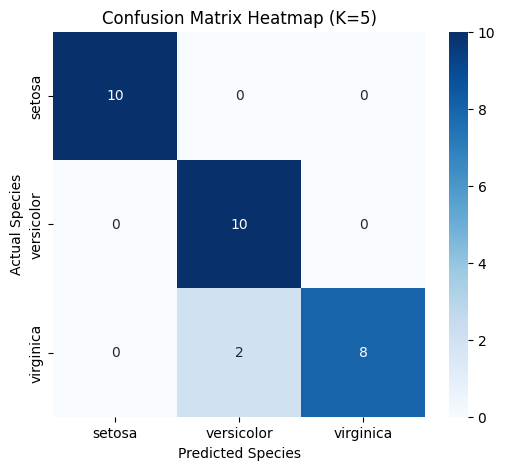

In [ ]:
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classifier.classes_,
            yticklabels=classifier.classes_)
plt.title("Confusion Matrix Heatmap (K=5)")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

The confusion matrix heatmap represents the performance of the KNN classification model with K = 5 on the Iris dataset.

The model correctly classified 10 Setosa flowers.

It correctly classified 10 Versicolor flowers.

It correctly classified 8 Virginica flowers.

2 Virginica flowers were incorrectly classified as Versicolor.

The model achieved an accuracy of 93.33%.

Therefore, the KNN model performed well in classifying the three Iris flower species, although it made two classification errors.

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [ ]:
error_rate = []
k_values = range(1, 31)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    pred_k = knn.predict(X_test_scaled)
    error_rate.append(np.mean(pred_k != y_test))   # error = wrong predictions / total

for k, e in zip(k_values, error_rate):
    print(f"K = {k:2d}  ->  Error Rate = {e:.4f}")

K =  1  ->  Error Rate = 0.0333
K =  2  ->  Error Rate = 0.0667
K =  3  ->  Error Rate = 0.0667
K =  4  ->  Error Rate = 0.0667
K =  5  ->  Error Rate = 0.0667
K =  6  ->  Error Rate = 0.0667
K =  7  ->  Error Rate = 0.0333
K =  8  ->  Error Rate = 0.0667
K =  9  ->  Error Rate = 0.0333
K = 10  ->  Error Rate = 0.0333
K = 11  ->  Error Rate = 0.0333
K = 12  ->  Error Rate = 0.0333
K = 13  ->  Error Rate = 0.0333
K = 14  ->  Error Rate = 0.0667
K = 15  ->  Error Rate = 0.0333
K = 16  ->  Error Rate = 0.0333
K = 17  ->  Error Rate = 0.0333
K = 18  ->  Error Rate = 0.0333
K = 19  ->  Error Rate = 0.0333
K = 20  ->  Error Rate = 0.0333
K = 21  ->  Error Rate = 0.0333
K = 22  ->  Error Rate = 0.1000
K = 23  ->  Error Rate = 0.0667
K = 24  ->  Error Rate = 0.1000
K = 25  ->  Error Rate = 0.1000
K = 26  ->  Error Rate = 0.1333
K = 27  ->  Error Rate = 0.1333
K = 28  ->  Error Rate = 0.1333
K = 29  ->  Error Rate = 0.1333
K = 30  ->  Error Rate = 0.1333


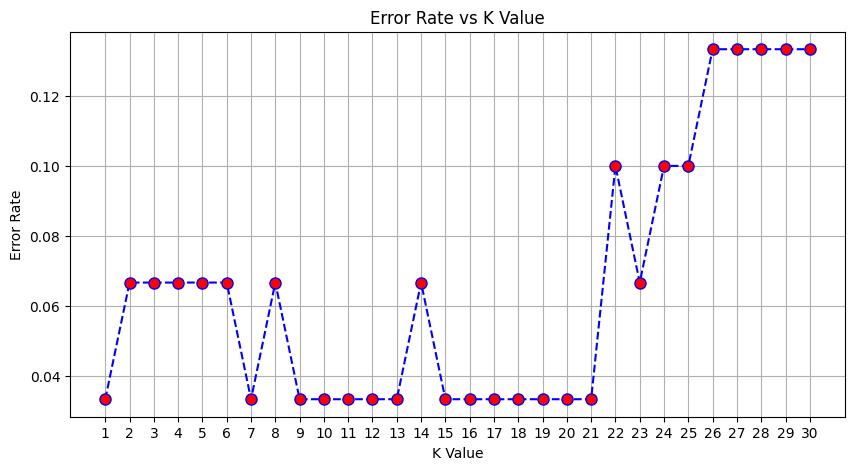

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(k_values, error_rate, color="blue", linestyle="dashed",
         marker="o", markerfacecolor="red", markersize=8)
plt.title("Error Rate vs K Value")
plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

The graph represents the relationship between K values and their corresponding error rates.

X-axis represents different K values.

Y-axis represents the error rate.

The lowest error rate is approximately 0.0333.

The error rate increases for larger K values, particularly after K = 21.

The graph helps identify suitable K values for the KNN model.

A lower point on the graph indicates better prediction performance.

In [ ]:
min_error = min(error_rate)
best_ks = [k for k, e in zip(k_values, error_rate) if e == min_error]
print("Minimum error rate:", min_error)
print("K values giving this error:", best_ks)

Minimum error rate: 0.03333333333333333
K values giving this error: [1, 7, 9, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 21]


The output shows that multiple K values produce the minimum error rate of 0.0333.

Among these values, the program selects K = 13 as the best K value using its selection rule.

This value is then used to train the final KNN model.

In [ ]:
odd_ks = [k for k in best_ks if k % 2 == 1]
best_k = odd_ks[len(odd_ks) // 2] if odd_ks else best_ks[0]
print("Chosen best K:", best_k)

Chosen best K: 13


In [ ]:
final_model = KNeighborsClassifier(n_neighbors=best_k)
final_model.fit(X_train_scaled, y_train)
final_pred = final_model.predict(X_test_scaled)
print("Final Accuracy with best K:", accuracy_score(y_test, final_pred))

Final Accuracy with best K: 0.9666666666666667


After selecting K = 13, the model is trained again and tested on the test dataset.

The final model achieves an accuracy of 96.67%, which is higher than the previous accuracy of 93.33% obtained using K = 5.

This indicates that K = 13 gives better results on this test set

In [ ]:
X2 = df[["petal_length", "petal_width"]].values
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)

sc2 = StandardScaler()
X2_train = sc2.fit_transform(X2_train)
X2_test = sc2.transform(X2_test)

knn2 = KNeighborsClassifier(n_neighbors=best_k)
knn2.fit(X2_train, y2_train)

KNeighborsClassifier(n_neighbors=13)

In [ ]:
x_min, x_max = X2_test[:, 0].min() - 1, X2_test[:, 0].max() + 1
y_min, y_max = X2_test[:, 1].min() - 1, X2_test[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                     np.arange(y_min, y_max, 0.02))
Z = knn2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

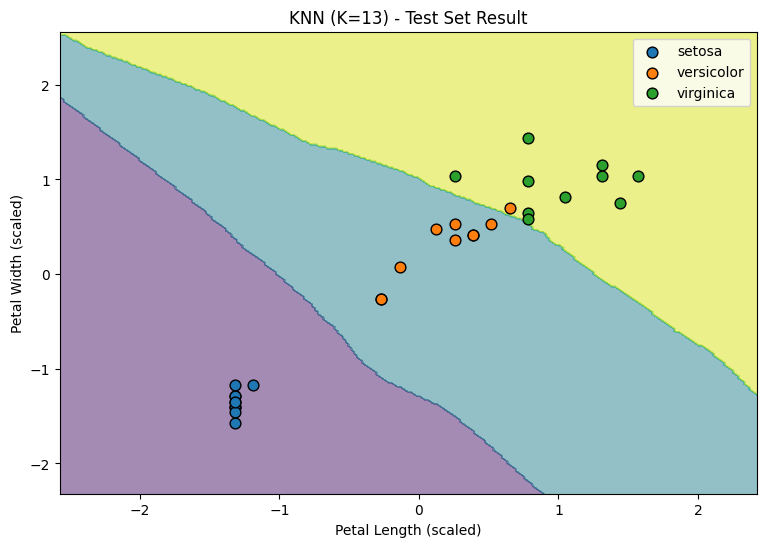

In [ ]:
classes = list(knn2.classes_)
Z_num = np.vectorize(classes.index)(Z)



plt.figure(figsize=(9, 6))
plt.contourf(xx, yy, Z_num, alpha=0.5, )

for i, c in enumerate(classes):
    plt.scatter(X2_test[y2_test == c,1], X2_test[y2_test == c,0],
                 edgecolor="black", s=60, label=c)

plt.title(f"KNN (K={best_k}) - Test Set Result")
plt.xlabel("Petal Length (scaled)")
plt.ylabel("Petal Width (scaled)")
plt.legend()
plt.show()

The graph visualizes the classification of Iris flowers using two features: Petal Length and Petal Width.

Red points represent Setosa.
Green points represent Versicolor.
Blue points represent Virginica.
Background colours represent the different classification regions predicted by the KNN model.

The graph shows that Setosa flowers are clearly separated from the other two species.

Versicolor and Virginica are also separated into different regions, although some points are close to their decision boundary.

This visualization helps us understand how the KNN algorithm classifies flowers based on their petal measurements